# End to end: mock, sample, results

The whole analysis on a mock observation whose answer is known: build the
data, sample the posterior, and score what comes out against the truth and
against the standard PCA + transfer-function pipeline run on the same data.

The model the sampler fits is

$$d = w\,\big(B\,(U_s s + U_f f) + U_g g\big) + n$$

* $s$ — the 21 cm signal, in Fourier space, with a diagonal covariance $S$
  set by one power-spectrum value per $k$-bin;
* $f$ — per-pixel amplitudes on `N_MODES` smooth (Legendre) frequency modes,
  with covariance $F$;
* $g$ — a handful of amplitudes on fixed ground-spill templates;
* $B$ — the chromatic primary beam, acting on the sky and on nothing else;
* $w$ — the footprint; $n$ — white noise.

Each Gibbs iteration draws $(s, f, g)$ given $(S, F)$ with one Gaussian
constrained realisation, then $S$ given $s$ (inverse-gamma) and $F$ given $f$
(inverse-Wishart). The posterior on $S$ *is* the power-spectrum estimate.

Everything is generated in place: H I and foregrounds from FastBox, the
systematic from the equations in `imgibbs.systematics`, a Gaussian beam and
radiometer noise (`imgibbs.mock`). Nothing is downloaded.

**Runtime.** The mock takes seconds; the chain takes about 10 s per sample on
a laptop with the beam on, so the default 300 samples is roughly an hour.
For longer chains run `scripts/run_gibbs.py` (the command is in §3) and set
`SAMPLE_HERE = False` to load the result here.

In [1]:
# Run from the repo without installing: `pip install -e ..` makes this unnecessary.
import sys, pathlib
_root = pathlib.Path.cwd().parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from imgibbs import (
    best_fit_amplitudes, binned_power, expected_hi_power, groundspill_basis,
    hi_cube, kbins_from_crop, legendre_basis, load_chain, load_mock,
    make_mock, run_chain, signal_prior,
)
from imgibbs.mock import noise_rms

In [2]:
# ---- The mock: what the sky and the instrument did ------------------------
MOCK_SEED  = 0                # master seed for HI, foreground, systematic, noise
SHAPE      = (70, 45, 250)    # RA x Dec pixels (0.3 deg) x channels (0.209 MHz)
BEAM_FWHM  = 1.5              # deg at the band centre; None for no beam
SYSTEMATIC = 'groundspill'    # 'groundspill', 'onef', 'leakage' or None

# ---- The model: what the sampler is told ----------------------------------
N_MODES    = 6                # Legendre foreground modes
MODEL_BEAM = True             # model the beam the mock was made with
MODEL_SYS  = True             # sample a systematic block

# ---- The chain ------------------------------------------------------------
N_SAMPLES  = 300
BURN       = 100              # left out of every posterior summary
CHAIN_SEED = 1
SAMPLE_HERE = True            # False: load a scripts/run_gibbs.py run instead
RUN_DIR    = '../outputs/end_to_end'

In [3]:
# Plot style: recessive chrome, categorical hues assigned in fixed order.
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, AXIS = '#e1e0d9', '#c3c2b7'

plt.rcParams.update({
    'figure.dpi': 140, 'savefig.dpi': 140,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.linewidth': 0.8, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'legend.frameon': False, 'font.size': 9, 'lines.linewidth': 1.8,
})

DIVERGING = LinearSegmentedColormap.from_list(
    'div', ['#0d366b', '#2a78d6', '#f0efec', '#e34948', '#8f2320'])


def bare(ax):
    for side in ('right', 'top'):
        ax.spines[side].set_visible(False)


def show_map(ax, field, title, lim=None, signed=True, cmap=None):
    # Map pixels outside the footprint are blank, not zero. Signed maps are
    # shown as fluctuations about their mean over the footprint.
    f = np.where(pix, field, np.nan).T
    if signed:
        f = f - np.nanmean(f)
        lim = lim or np.nanmax(np.abs(f))
        im = ax.imshow(f, origin='lower', cmap=DIVERGING, aspect='equal',
                       norm=TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim))
    else:
        im = ax.imshow(f, origin='lower', cmap=cmap or 'inferno',
                       aspect='equal')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(title, fontsize=9, loc='left')
    return im

## 1. The mock

`make_mock` builds every term of the data model on the MeerKAT L band,
970.9–1023.0 MHz ($z$ = 0.39–0.46):

| term | what | from |
|---|---|---|
| H I | lognormal density, H I bias, linear RSD, $\bar T_b$ | `fastbox.tracers.generate_hi_mock` |
| foreground | Galactic synchrotron + point sources, Santos et al. (2005) angular spectra, power law per pixel with a varying index; CMB monopole | `fastbox.foregrounds.ForegroundModel` |
| beam | Gaussian, FWHM $\propto 1/\nu$ | `imgibbs.gaussian_beam` |
| systematic | ground spill: a smooth spillover plus a 17.5 MHz standing-wave ripple, constant + scan gradient | `imgibbs.groundspill_cube` |
| noise | $T_{\rm sys}/\sqrt{\Delta\nu\,\Delta t}$, 16 K, 1000 s | — |
| footprint | a tilted drift-scan band with rounded ends | `imgibbs.drift_footprint` |

Each term has its own seed, spawned from `MOCK_SEED`, so switching the
systematic off leaves the H I, foreground and noise realisations untouched.

In [4]:
if SAMPLE_HERE:
    mock = make_mock(SHAPE, seed=MOCK_SEED, beam_fwhm=BEAM_FWHM,
                     systematic=SYSTEMATIC)
else:
    mock = load_mock(f'{RUN_DIR}/mock.npz')     # the run's own mock
    SHAPE, SYSTEMATIC = mock.shape, mock.config['systematic']

grid, cube, mask = mock.grid, mock.cube, mock.mask
obs = mask > 0                  # observed voxels
pix = obs[:, :, 0]              # observed map pixels
print(mock.summary())

grid         : (70, 45, 250), 970.94-1022.98 MHz, z 0.389-0.463
footprint    : 62.7% of the map
HI           : rms 7.992e-04 K
foreground   : rms 3.275e-02 K (41x the HI), mean 3.562 K
beam         : Gaussian, FWHM 1.5 deg at 997.0 MHz
systematic   : groundspill, rms 1.0e-03 K, 4 amplitudes
noise        : rms 1.107e-03 K


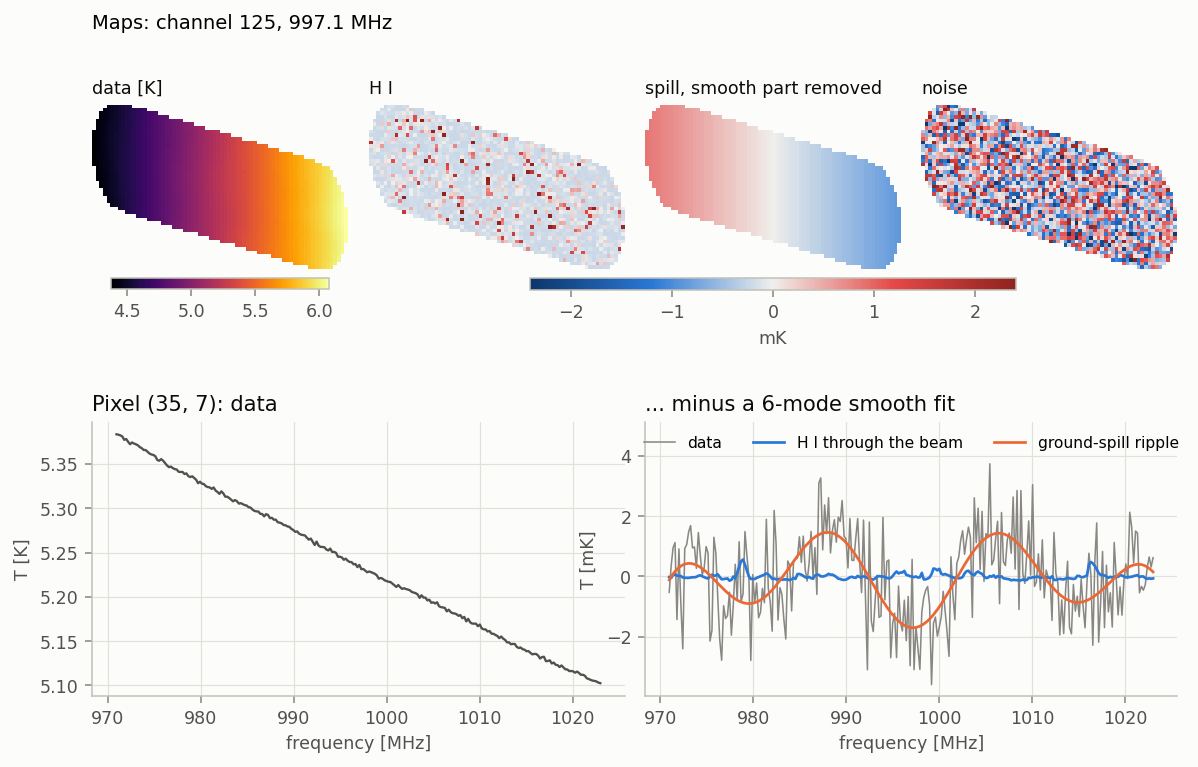

In [5]:
chan = SHAPE[2] // 2
px = tuple(int(i) for i in np.argwhere(pix)[pix.sum() // 2])   # mid-footprint
mK = 1e3
nu = grid.freqs
ev = legendre_basis(SHAPE[2], N_MODES)


def smooth_removed(c):
    # c minus its best N_MODES-mode smooth spectrum, pixel by pixel.
    flat = c.reshape(-1, SHAPE[2])
    return (flat - (flat @ ev.T) @ ev).reshape(c.shape)


fig = plt.figure(figsize=(10, 5.6))
gs = fig.add_gridspec(2, 4, height_ratios=[0.8, 1], hspace=0.45, wspace=0.08)

im = show_map(fig.add_subplot(gs[0, 0]), cube[:, :, chan], 'data [K]',
              signed=False)
fig.colorbar(im, ax=im.axes, orientation='horizontal', pad=0.04, shrink=0.85)
lim = 3 * mock.hi.std() * mK
ripple = smooth_removed(mock.systematic) if SYSTEMATIC else mock.systematic
for i, (field, name) in enumerate([(mock.hi, 'H I'),
                                   (ripple, 'spill, smooth part removed'),
                                   (mock.noise, 'noise')]):
    im = show_map(fig.add_subplot(gs[0, i + 1]), field[:, :, chan] * mK,
                  name, lim=lim)
cb = fig.colorbar(im, ax=fig.axes[-3:], orientation='horizontal', pad=0.04,
                  shrink=0.6, aspect=40)
cb.set_label('mK')

# One line of sight: the foreground dwarfs everything, until its smooth
# part is fitted out.
spec = cube[px]
resid = spec - ev.T @ (ev @ spec)
sky_resid = (mock.sky[px] - ev.T @ (ev @ mock.sky[px]))
sys_resid = mock.systematic[px] - ev.T @ (ev @ mock.systematic[px])

ax = fig.add_subplot(gs[1, :2])
ax.plot(nu, spec, color=INK2, lw=1.2)
ax.set_xlabel('frequency [MHz]'); ax.set_ylabel('T [K]')
ax.set_title(f'Pixel {px}: data', loc='left')
bare(ax)

ax = fig.add_subplot(gs[1, 2:])
ax.plot(nu, resid * mK, color=MUTED, lw=0.8, label='data')
ax.plot(nu, sky_resid * mK, color=BLUE, lw=1.4, label='H I through the beam')
ax.plot(nu, sys_resid * mK, color=ORANGE, lw=1.4, label='ground-spill ripple')
ax.set_xlabel('frequency [MHz]'); ax.set_ylabel('T [mK]')
ax.set_title(f'... minus a {N_MODES}-mode smooth fit', loc='left')
ax.legend(loc='upper center', ncols=3, bbox_to_anchor=(0.5, 1.0), fontsize=8)
ax.set_ylim(np.array(ax.get_ylim()) * [1, 1.25])
bare(ax)
fig.suptitle(f'Maps: channel {chan}, {nu[chan]:.1f} MHz', x=0.125, ha='left',
             fontsize=10, y=0.98)
plt.show()

The data are a few kelvin of foreground; the H I is a millikelvin. Fitting a
smooth spectrum out of each pixel leaves the H I, the noise and the ripple,
all at about the same level. The *smooth* part of the spill (0.5 K) is gone
with the foreground — the ripple is what survives, and it is the reason the
systematic block exists (`2_systematics.ipynb`).

## 2. What the sampler is given

* **$k$-bins.** `kbins_from_crop` takes $k_{\min}$ from the footprint rather
  than the box, drops the $k_\parallel = 0$ plane (exactly degenerate with the
  foreground) and picks the bin count from occupancy.
* **A starting $S$.** The *expected* H I power under the fiducial cosmology —
  the mean of 8 realisations independent of the one in the mock — not the
  power of the realisation the data contain.
* **The foreground basis**, `N_MODES` orthonormal Legendre polynomials, with
  the prior centred on zero (with a beam, the data's own projection is
  already beamed, and centring on it would apply $B$ twice).
* **The beam**, identical to the one the mock was made with.
* **A ground-spill block**: {constant, scan gradient} × {cos, sin} at the
  ripple period, plus an *unbeamed* smooth template per spatial term. Without
  a beam the foreground block would absorb the smooth spill; with one it
  cannot, because the spill enters after the beam and $B U_f f$ is beamed.
  The block is integrated out of the solve and $g$ drawn afterwards
  (`docs/STATUS.md`, "The beam in the MODEL", finding 9).

In [6]:
sig_k, idxs, kbin_meta = kbins_from_crop(cube, grid.box_dims, max_bins=5)
dc = kbin_meta['dc_index']
occupied = np.unique(idxs)[1:]
n_bins = len(sig_k)

true_pk = binned_power(mock.hi, sig_k, idxs)                 # the answer
exp_pk, exp_sd = expected_hi_power(grid, sig_k, idxs)        # the start
S0 = signal_prior(exp_pk, idxs, dc)

evecs = legendre_basis(SHAPE[2], N_MODES)
w = mask.ravel()
N = noise_rms() ** 2
beam = mock.beam if MODEL_BEAM else None

if not MODEL_SYS or SYSTEMATIC is None:
    sys_basis = G = None
elif SYSTEMATIC == 'groundspill':
    smooth = beam is not None
    sys_basis = groundspill_basis(grid.freqs, SHAPE,
                                  period=mock.config['sys_kwargs']['period'],
                                  include_smooth=smooth)
    G = np.full(sys_basis.g_shape, 1e-2 ** 2)    # ripple: 10 mK prior std
    if smooth:
        G[:, 0] = 10.0 ** 2                      # smooth spill: 10 K
    G = G.ravel()
else:
    # 1/f or leakage: model with the basis the mock was drawn from.
    sys_basis = mock.sys_basis
    G = np.full(sys_basis.n_params, 1e-2 ** 2)

# Where can the data constrain S at all? Per mode, the data-to-prior precision
# ratio is q = <w> |B|^2 P / N, with |B|^2 averaged over the band. A bin of
# modes then pins P to a fractional width of about
#     sigma_P / P = [ sum_modes (q / (1 + q))^2 / 2 ]^(-1/2)
# (halved for the conjugate pairs the full FFT grid counts twice). This
# ignores the foreground, so it is optimistic at the lowest k.
b2 = ((beam.full_transfer() ** 2).mean(axis=2) if beam is not None
      else np.ones(SHAPE[:2]))
b2_mode = np.broadcast_to(b2[:, :, None], SHAPE).ravel()
q = w.mean() * b2_mode * signal_prior(true_pk, idxs, dc) / N
sigma_fisher = np.array([1 / np.sqrt(0.25 * np.sum((q[idxs == b] / (1 + q[idxs == b])) ** 2))
                         for b in occupied])
beam_window = np.array([b2_mode[idxs == b].mean() for b in occupied])
SIGMA_MAX = 0.15
constrained = sigma_fisher < SIGMA_MAX

print('\n bin      k     true P(k)   start/true   data alone: sigma_P/P')
for i in range(n_bins):
    print(f'  {i}   {sig_k[i]:6.3f}   {true_pk[i]:.3e}     {exp_pk[i] / true_pk[i]:5.2f}'
          f'        {sigma_fisher[i]:6.2f}' + ('' if constrained[i] else '   <- prior-dominated'))
if sys_basis is not None:
    print(f'\nsystematic block: {sys_basis.n_params} amplitudes '
          f'({sys_basis.n_s} spatial x {sys_basis.n_t} spectral)')

[kbins] (70, 45, 250) box (601,386,254) Mpc
[kbins] footprint 12.2 x 4.8 deg = 348 x 137 Mpc, fill 62.7%
[kbins] k_min 0.0460 (short axis), k_max 3.129, 5 bins, kz=0 dropped
[kbins] modes/bin [934, 13200, 108186, 209190, 452778]
[kbins] excluded 3212 of 787500 voxels (0.4%) -> idxs 0



 bin      k     true P(k)   start/true   data alone: sigma_P/P
  0    0.070   7.341e-06      0.99          0.13
  1    0.163   4.188e-06      1.02          0.11
  2    0.379   2.627e-06      1.01          0.10
  3    0.882   5.453e-07      1.06          0.20   <- prior-dominated
  4    2.052   6.109e-08      1.00          1.04   <- prior-dominated

systematic block: 6 amplitudes (2 spatial x 3 spectral)


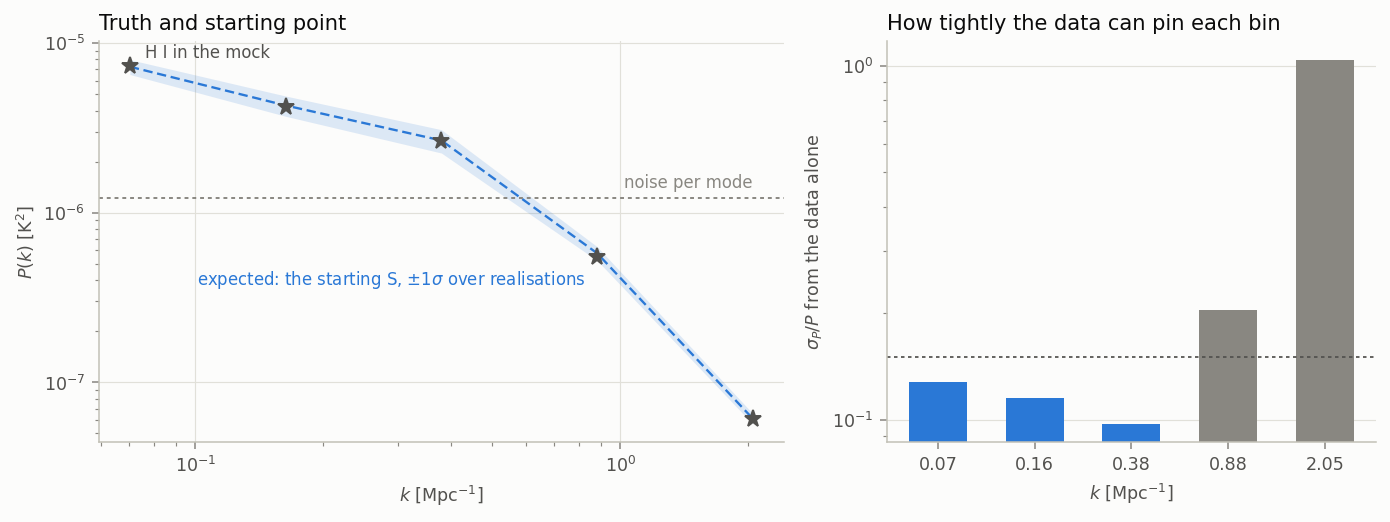

In [7]:
fig, (ax, axf) = plt.subplots(1, 2, figsize=(10, 3.8),
                              gridspec_kw={'width_ratios': [1.4, 1]})
ax.fill_between(sig_k, exp_pk - exp_sd, exp_pk + exp_sd, color=BLUE,
                alpha=0.15, lw=0)
ax.plot(sig_k, exp_pk, color=BLUE, lw=1.2, ls=(0, (4, 2)))
ax.plot(sig_k, true_pk, color=INK2, marker='*', ms=9, lw=0)
ax.axhline(N, color=MUTED, lw=1.0, ls=(0, (2, 2)))
ax.annotate('H I in the mock', xy=(sig_k[0], true_pk[0]), xytext=(8, 4),
            textcoords='offset points', color=INK2, fontsize=8.5)
ax.annotate(r'expected: the starting S, $\pm1\sigma$ over realisations',
            xy=(sig_k[3], exp_pk[3]), xytext=(-6, -16),
            textcoords='offset points', color=BLUE, fontsize=8.5, ha='right')
ax.annotate('noise per mode', xy=(sig_k[-1], N), xytext=(0, 5),
            textcoords='offset points', color=MUTED, fontsize=8.5, ha='right')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]'); ax.set_ylabel(r'$P(k)$ [K$^2$]')
ax.set_title('Truth and starting point', loc='left')
bare(ax)

axf.bar(np.arange(n_bins), sigma_fisher, width=0.6,
        color=[BLUE if c else MUTED for c in constrained])
axf.axhline(SIGMA_MAX, color=INK2, lw=0.9, ls=(0, (2, 2)))
axf.set_yscale('log')
axf.set_xticks(np.arange(n_bins))
axf.set_xticklabels([f'{k:.2f}' for k in sig_k])
axf.set_xlabel(r'$k$ [Mpc$^{-1}$]')
axf.set_ylabel(r'$\sigma_P / P$ from the data alone')
axf.set_title('How tightly the data can pin each bin', loc='left')
axf.grid(axis='x', visible=False)
bare(axf)
fig.tight_layout()
plt.show()

The high-$k$ shells are almost all transverse modes past the beam cutoff,
where the beamed H I is far below the noise. A bin's power can still be
pinned down by the few thousand modes the beam lets through, which is what
the right panel estimates; above ~15% the chain barely moves off its start in
any practical chain length (`docs/STATUS.md` found exactly this split by
starting chains from 0.1x and 10x the power). Those bins are greyed out
below: what the chain reports there is its starting point, not a
measurement. Judge the method on the blue bins.

## 3. Sampling

`run_chain` is the same function `scripts/run_gibbs.py` calls. For a longer
chain, run the identical configuration from the repository root,

```bash
python scripts/run_gibbs.py 6 --n-samples 2000 --seed 1 --burn 300 \
    --out outputs/end_to_end --save-x-every 0 \
    --mock-beam-fwhm 1.5 --mock-systematic groundspill \
    --beam-fwhm 1.5 --groundspill
```

then set `SAMPLE_HERE = False` above and re-run this notebook.

In [8]:
if SAMPLE_HERE:
    chain = run_chain(cube, w, evecs, S0, sig_k, idxs, dc, N, N_SAMPLES,
                      seed=CHAIN_SEED, sys_basis=sys_basis, G=G, beam=beam,
                      mean_from=BURN)
    print(f'{N_SAMPLES} samples in {chain.elapsed / 60:.1f} min '
          f'({chain.elapsed / N_SAMPLES:.1f} s each, median '
          f'{np.median(chain.matvecs):.0f} matvecs per solve)')
else:
    chain = load_chain(RUN_DIR, f'_LP{N_MODES}_')
    N_SAMPLES, BURN = len(chain.pk), chain.mean_from
    print(f'loaded {N_SAMPLES} samples from {RUN_DIR}, burn-in {BURN}')

post = chain.pk[BURN:]                       # post-burn-in S draws

S step       : drawn from beam-visible modes only, 934/934, 5556/13200, 10574/108186, 23806/209190, 53439/452778
fg prior     : centred on zero


fg precond   : exact-mask block, 3 modes, 5 beam groups, built in 33 s, refreshed every 20


300 samples in 47.6 min (9.5 s each, median 32 matvecs per solve)


## 4. Results

### 4.1 Traces

Every chain starts at the expected power, so the question the traces answer
is whether it moves off that start to where the data put it.

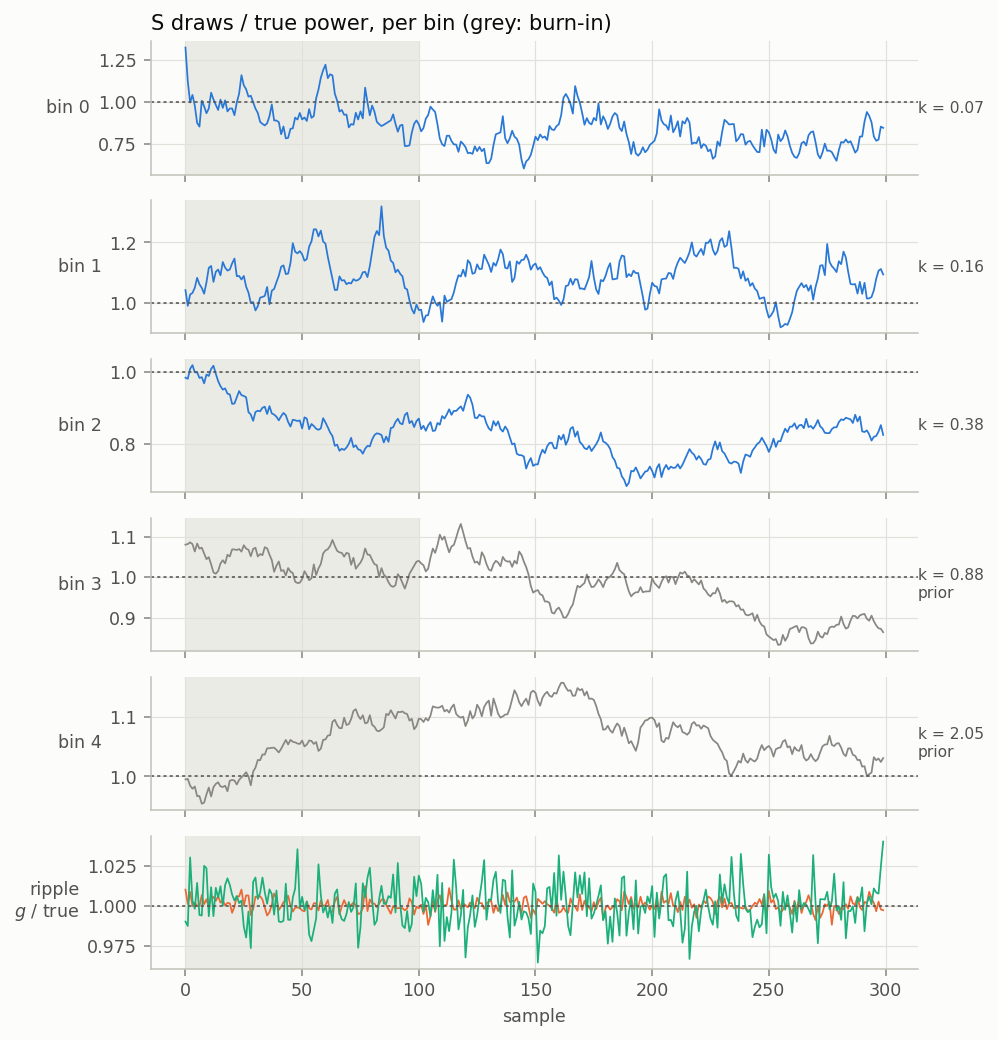

In [9]:
n_rows = n_bins + (sys_basis is not None)
fig, axes = plt.subplots(n_rows, 1, figsize=(7.2, 1.15 * n_rows + 0.6),
                         sharex=True)
it = np.arange(len(chain.pk))
for i, ax in enumerate(axes[:n_bins]):
    ax.axvspan(0, BURN, color=GRID, alpha=0.6, lw=0)
    ax.plot(it, chain.pk[:, i] / true_pk[i],
            color=BLUE if constrained[i] else MUTED, lw=0.9)
    ax.axhline(1.0, color=INK2, lw=0.8, ls=(0, (2, 2)))
    ax.set_ylabel(f'bin {i}', rotation=0, ha='right', va='center')
    ax.text(1.0, 0.5, f'k = {sig_k[i]:.2f}' + ('' if constrained[i] else '\nprior'),
            transform=ax.transAxes, fontsize=8, color=INK2, va='center',
            ha='left')
    bare(ax)
axes[0].set_title('S draws / true power, per bin (grey: burn-in)', loc='left')

if sys_basis is not None:
    g_target = best_fit_amplitudes(sys_basis, mock.systematic)
    g = chain.g.reshape(len(chain.g), -1)
    tgt = g_target.ravel()
    ripple = [j for j in range(len(tgt)) if abs(tgt[j]) > 1e-6 * np.abs(tgt).max()
              and (sys_basis.n_t < 3 or j % sys_basis.n_t != 0)]
    ax = axes[-1]
    ax.axvspan(0, BURN, color=GRID, alpha=0.6, lw=0)
    for c, j in zip((ORANGE, AQUA, YELLOW, BLUE), ripple):
        ax.plot(it, g[:, j] / tgt[j], color=c, lw=0.9)
    ax.axhline(1.0, color=INK2, lw=0.8, ls=(0, (2, 2)))
    ax.set_ylabel('ripple\n$g$ / true', rotation=0, ha='right', va='center')
    bare(ax)
axes[-1].set_xlabel('sample')
fig.tight_layout()
plt.show()

### 4.2 The power spectrum

The posterior on $S$, after burn-in, against the power of the H I actually in
the mock. The box is the 16th–84th percentile of the draws, which is the
posterior width given this realisation — not including the cosmic variance of
the realisation itself.

**Successive draws are strongly correlated**, so the chain is shorter than it
looks. The table gives the integrated autocorrelation time $\tau$ of each
bin's trace, the effective number of independent samples, and the Monte
Carlo error on the median that follows from it. On a short chain $\tau$ is
itself underestimated (by about half when the chain is ten $\tau$ long), so
read it as a lower bound. Where it is a sizeable fraction of the chain, the chain has not explored the posterior yet and the
recovered value can be off by more than the box suggests — run longer.

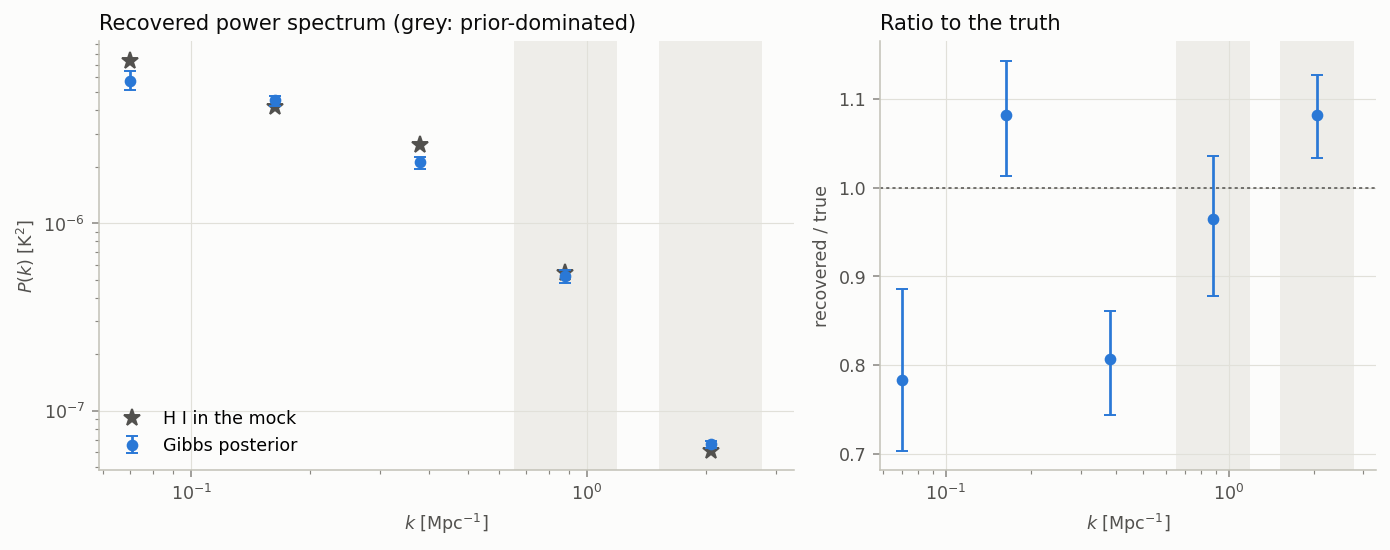

 bin      k     recovered / true            tau    ESS   MC error   (200 post-burn-in draws)
  0    0.070    0.78  (+0.10 / -0.08)      7.2   27.9   0.02
  1    0.163    1.08  (+0.06 / -0.07)      5.0   39.7   0.01
  2    0.379    0.81  (+0.05 / -0.06)     15.1   13.2   0.02
  3    0.882    0.96  (+0.07 / -0.09)     27.3    7.3   0.03   prior-dominated
  4    2.052    1.08  (+0.04 / -0.05)     24.9    8.0   0.02   prior-dominated


In [10]:
lo, med, hi = np.percentile(post, [16, 50, 84], axis=0)

fig, (ax, axr) = plt.subplots(1, 2, figsize=(10, 4.0),
                              gridspec_kw={'width_ratios': [1.4, 1]})
for a in (ax, axr):
    for i in np.where(~constrained)[0]:
        a.axvspan(sig_k[i] / 1.35, sig_k[i] * 1.35, color=GRID, alpha=0.5, lw=0)
ax.plot(sig_k, true_pk, color=INK2, marker='*', ms=9, lw=0, label='H I in the mock')
ax.errorbar(sig_k, med, yerr=[med - lo, hi - med], color=BLUE, marker='o',
            ms=5, lw=0, elinewidth=1.4, capsize=3, label='Gibbs posterior')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]'); ax.set_ylabel(r'$P(k)$ [K$^2$]')
ax.set_title('Recovered power spectrum (grey: prior-dominated)', loc='left')
ax.legend(loc='lower left')
bare(ax)

axr.axhline(1.0, color=INK2, lw=0.8, ls=(0, (2, 2)))
axr.errorbar(sig_k, med / true_pk, yerr=[(med - lo) / true_pk, (hi - med) / true_pk],
             color=BLUE, marker='o', ms=5, lw=0, elinewidth=1.4, capsize=3)
axr.set_xscale('log')
axr.set_xlabel(r'$k$ [Mpc$^{-1}$]'); axr.set_ylabel('recovered / true')
axr.set_title('Ratio to the truth', loc='left')
bare(axr)
fig.tight_layout()
plt.show()



def tau_int(x, c=5.0):
    # Integrated autocorrelation time, Sokal's self-consistent window.
    x = x - x.mean()
    n = len(x)
    f = np.fft.rfft(x, 2 * n)
    acf = np.fft.irfft(f * np.conj(f))[:n]
    acf /= acf[0]
    taus = 2 * np.cumsum(acf) - 1
    window = np.arange(n) >= c * taus
    return float(taus[np.argmax(window)] if window.any() else taus[-1])


tau = np.array([tau_int(post[:, i]) for i in range(n_bins)])
ess = len(post) / tau
mc_err = (hi - lo) / 2 / np.sqrt(ess)

print(f' bin      k     recovered / true            tau    ESS   MC error'
      f'   ({len(post)} post-burn-in draws)')
for i in range(n_bins):
    print(f'  {i}   {sig_k[i]:6.3f}   {med[i] / true_pk[i]:5.2f}  '
          f'(+{(hi[i] - med[i]) / true_pk[i]:.2f} / -{(med[i] - lo[i]) / true_pk[i]:.2f})'
          f'   {tau[i]:6.1f}  {ess[i]:5.1f}   {mc_err[i] / true_pk[i]:.2f}'
          + ('' if constrained[i] else '   prior-dominated'))

### 4.3 The maps

The posterior-mean signal $\langle s\rangle$ is a Wiener filter: in modes the
data cannot see — here the small scales the beam erased — it shrinks to
zero. So the like-for-like truth is the H I *through the beam*.

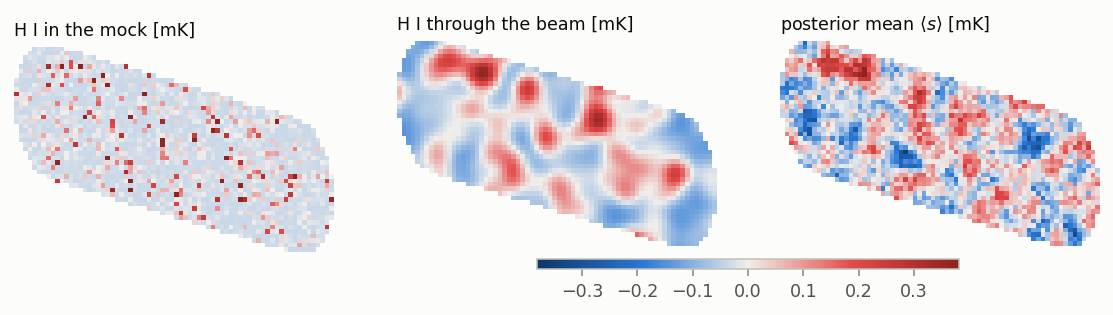

correlation over the footprint, all channels:
  <s> vs H I               : 0.125


  <s> vs H I through beam  : 0.483


In [11]:
s_mean = chain.signal_mean
hi_b = beam.apply(mock.hi) if beam is not None else mock.hi


def corr(a, b):
    a, b = a[obs] - a[obs].mean(), b[obs] - b[obs].mean()
    return float(a @ b / np.sqrt((a @ a) * (b @ b)))


fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
lim = 3 * hi_b[obs].std() * mK
show_map(axes[0], mock.hi[:, :, chan] * mK, 'H I in the mock [mK]',
         lim=3 * mock.hi.std() * mK)
show_map(axes[1], hi_b[:, :, chan] * mK, 'H I through the beam [mK]', lim=lim)
im = show_map(axes[2], s_mean[:, :, chan] * mK,
              r'posterior mean $\langle s\rangle$ [mK]', lim=lim)
fig.colorbar(im, ax=axes[1:], orientation='horizontal', pad=0.04,
             shrink=0.6, aspect=40)
plt.show()

print(f'correlation over the footprint, all channels:')
print(f'  <s> vs H I               : {corr(s_mean, mock.hi):.3f}')
print(f'  <s> vs H I through beam  : {corr(s_mean, hi_b):.3f}')

### 4.4 The systematic

$g$ against the projection of the injected spill onto the model's own
templates (`best_fit_amplitudes`), which is the best this block could do.

The spatially *constant* smooth template is left out: a spectrum that is the
same in every pixel has $k_\perp = 0$, which the beam passes untouched, so
$B U_f f$ reproduces it exactly and its amplitude is not identifiable. That
is harmless — whatever $g$ does not take, $f$ does.

In [12]:
if sys_basis is None:
    print('no systematic block in this run')
else:
    g_post = chain.g[BURN:].reshape(len(chain.g) - BURN, -1)
    gm, gs = g_post.mean(axis=0), g_post.std(axis=0)
    tgt = best_fit_amplitudes(sys_basis, mock.systematic).ravel()
    names = (['smooth', 'cos', 'sin'] if sys_basis.n_t == 3 else
             [f't{t}' for t in range(sys_basis.n_t)])
    print(' spatial  spectral      true          posterior          pull')
    for j in range(len(tgt)):
        s_, t_ = divmod(j, sys_basis.n_t)
        if sys_basis.n_t == 3 and s_ == 0 and t_ == 0:
            continue                    # constant x smooth: degenerate with f
        pull = (gm[j] - tgt[j]) / gs[j] if gs[j] > 0 else np.nan
        print(f'   {["const", "grad"][s_] if s_ < 2 else s_:>5}   {names[t_]:>6}   '
              f'{tgt[j]: .4e}   {gm[j]: .4e} +- {gs[j]:.1e}   {pull:6.2f}')

 spatial  spectral      true          posterior          pull
   const      cos    9.5784e-04    9.5821e-04 +- 3.7e-06     0.10
   const      sin   -1.2684e-17    5.5635e-06 +- 3.6e-06     1.56
    grad   smooth    4.9748e-01    4.9623e-01 +- 1.6e-03    -0.78
    grad      cos    2.8735e-04    2.8753e-04 +- 3.9e-06     0.04
    grad      sin   -1.6586e-17    3.4745e-06 +- 3.8e-06     0.92


## 5. Against the standard pipeline: PCA + transfer function

The same data through the usual route: remove the leading `N_MODES`
frequency eigenmodes (PCA) from the observed pixels, measure the power of
what is left, and correct it for

1. **noise** — the noise power that survives the same projection, from
   noise-only realisations (the mock knows the noise level; on sky you would
   cross-correlate independent splits);
2. **signal loss** — the transfer function of Cunnington et al. (2023):
   inject independent mock H I, beamed, re-clean, and take
   $T(k) = P(X^{\rm clean}_m - X^{\rm clean},\,X_m)\,/\,P(X_m, X_m)$, the
   cross-power keeping foreground and noise out of the numerator;
3. **the beam** — divide by the bin-averaged $|B|^2$.

All on the same $k$-bins, with a footprint estimator normalised by
$\langle w^2\rangle$. The injected mocks are independent FastBox
realisations from the same generator as the H I in the data, so they share
its lognormal phase structure — phase-randomised Gaussian mocks bias this
estimator by 1.3–1.8x (`docs/STATUS.md`; `scripts/pca_benchmark.py` computes
the exact transfer function instead). PCA knows nothing about the ground-spill ripple; it
removes it only if the ripple ranks among the leading eigenmodes.

In [13]:
N_PCA = N_MODES
N_TF_MOCKS = 30
N_NOISE = 10
w2 = mask.mean()


def pk_fp(a, b=None):
    # Binned (cross-)power over the footprint, normalised by <w^2>.
    A = np.fft.fftn((a - a[obs].mean()) * mask, norm='ortho').ravel()
    B = A if b is None else np.fft.fftn((b - b[obs].mean()) * mask,
                                        norm='ortho').ravel()
    p = (A * np.conj(B)).real
    return np.array([p[idxs == i].mean() for i in occupied]) / w2


def pca_modes(c):
    d = c[pix]
    d = d - d.mean(axis=0)
    return np.linalg.svd(d, full_matrices=False)[2][:N_PCA]   # (N_PCA, Nz)


def project(c, A):
    d = c[pix]
    d = d - d.mean(axis=0)
    out = np.zeros_like(c)
    out[pix] = d - (d @ A.T) @ A
    return out


A_data = pca_modes(cube)
cleaned = project(cube, A_data)
pk_clean = pk_fp(cleaned)

rng = np.random.default_rng(2026)
pk_noise_all = np.array([pk_fp(project(rng.normal(scale=noise_rms(), size=SHAPE) * mask,
                                       A_data)) for _ in range(N_NOISE)])
pk_noise = pk_noise_all.mean(axis=0)

T = np.zeros((N_TF_MOCKS, n_bins))
for i in range(N_TF_MOCKS):
    m = hi_cube(grid, seed=10_000 + i)            # independent of the mock's H I
    mb = beam.apply(m) if beam is not None else m
    inj = cube + mb * mask
    T[i] = pk_fp(project(inj, pca_modes(inj)) - cleaned, mb) / pk_fp(mb)
T_mean, T_sd = T.mean(axis=0), T.std(axis=0)

pk_pca = (pk_clean - pk_noise) / T_mean / beam_window
# Two error terms: the scatter of T over the injected mocks, and the scatter
# of the noise power itself -- the data hold one noise realisation, and its
# power is only known to the spread between realisations.
pk_pca_err = np.hypot(np.abs(pk_pca) * T_sd / T_mean,
                      pk_noise_all.std(axis=0) / T_mean / beam_window)

print(' bin      k      T(k)     noise/clean   PCA / true   Gibbs / true')
for i in range(n_bins):
    print(f'  {i}   {sig_k[i]:6.3f}   {T_mean[i]:5.3f}    {pk_noise[i] / pk_clean[i]:6.3f}'
          f'       {pk_pca[i] / true_pk[i]:6.2f}      {med[i] / true_pk[i]:6.2f}'
          + ('' if constrained[i] else '   prior-dominated'))

 bin      k      T(k)     noise/clean   PCA / true   Gibbs / true
  0    0.070   0.611     0.383         1.14        0.78
  1    0.163   0.776     0.853         1.17        1.08
  2    0.379   0.818     0.994         0.25        0.81
  3    0.882   0.842     1.011        -1.80        0.96   prior-dominated
  4    2.052   0.877     1.018       -22.74        1.08   prior-dominated


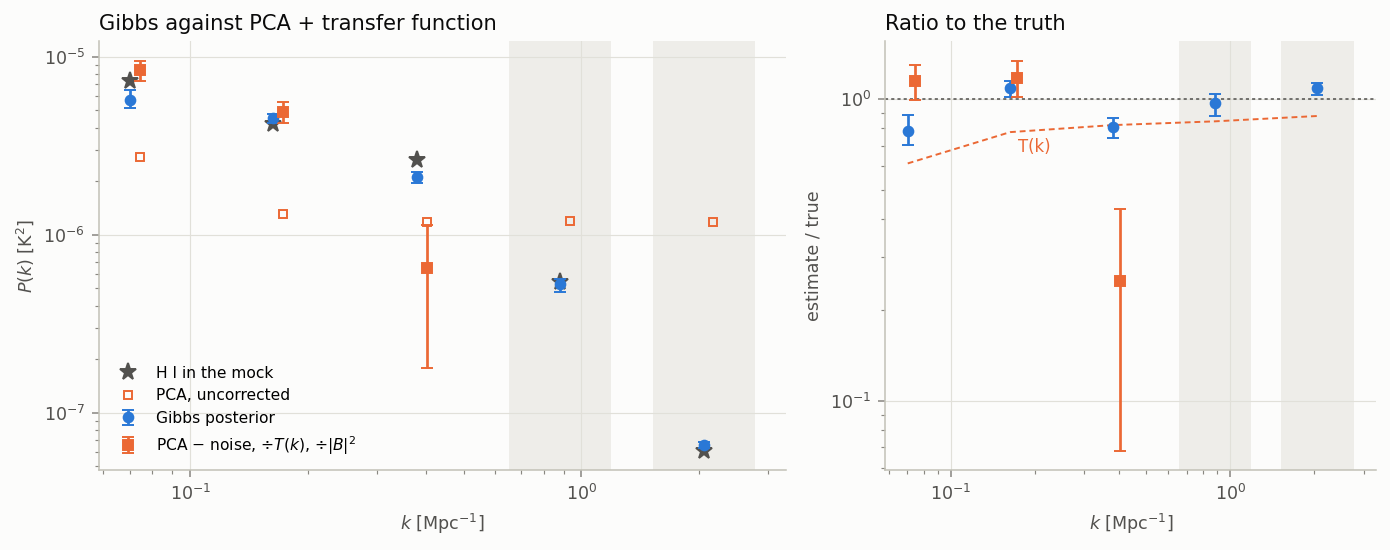

In [14]:
fig, (ax, axr) = plt.subplots(1, 2, figsize=(10, 4.0),
                              gridspec_kw={'width_ratios': [1.4, 1]})
for a in (ax, axr):
    for i in np.where(~constrained)[0]:
        a.axvspan(sig_k[i] / 1.35, sig_k[i] * 1.35, color=GRID, alpha=0.5, lw=0)

ax.plot(sig_k, true_pk, color=INK2, marker='*', ms=9, lw=0, label='H I in the mock')
ax.errorbar(sig_k, med, yerr=[med - lo, hi - med], color=BLUE, marker='o', ms=5,
            lw=0, elinewidth=1.4, capsize=3, label='Gibbs posterior')
ok = pk_pca > 0
ax.errorbar(sig_k[ok] * 1.06, pk_pca[ok], yerr=pk_pca_err[ok], color=ORANGE,
            marker='s', ms=5, lw=0, elinewidth=1.4, capsize=3,
            label=r'PCA $-$ noise, $\div T(k)$, $\div |B|^2$')
ax.plot(sig_k * 1.06, pk_clean, color=ORANGE, marker='s', ms=4, mfc='none',
        lw=0, label='PCA, uncorrected')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]'); ax.set_ylabel(r'$P(k)$ [K$^2$]')
ax.set_title('Gibbs against PCA + transfer function', loc='left')
ax.legend(loc='lower left', fontsize=8)
bare(ax)

axr.axhline(1.0, color=INK2, lw=0.8, ls=(0, (2, 2)))
axr.errorbar(sig_k, med / true_pk, yerr=[(med - lo) / true_pk, (hi - med) / true_pk],
             color=BLUE, marker='o', ms=5, lw=0, elinewidth=1.4, capsize=3)
axr.errorbar(sig_k[ok] * 1.06, pk_pca[ok] / true_pk[ok],
             yerr=pk_pca_err[ok] / true_pk[ok], color=ORANGE, marker='s', ms=5,
             lw=0, elinewidth=1.4, capsize=3)
axr.plot(sig_k, T_mean, color=ORANGE, lw=1.0, ls=(0, (3, 2)))
axr.annotate('T(k)', xy=(sig_k[1], T_mean[1]), xytext=(4, -10),
             textcoords='offset points', color=ORANGE, fontsize=8.5)
axr.set_xscale('log'); axr.set_yscale('log')
axr.set_xlabel(r'$k$ [Mpc$^{-1}$]'); axr.set_ylabel('estimate / true')
axr.set_title('Ratio to the truth', loc='left')
bare(axr)
fig.tight_layout()
plt.show()

## 6. Reading this, and where to go next

* **Only the constrained bins test the method.** In the prior-dominated bins
  the chain reports its starting point, which here is the expected power and
  so lands near the truth for the wrong reason. Start from
  `--S-start-scale 0.1` and `10` with `scripts/run_gibbs.py`: where both
  starts meet, the data set the answer.
* **Chain length.** 300 samples is enough to see the behaviour, not to
  quote numbers: with a beam the constrained bins mix slowly (the beam
  leaves the `S` step a few percent of each bin's modes), and $\tau$ in
  §4.2 says how slowly. `docs/STATUS.md` uses 1500–3000 samples with 300
  burn-in.
* **The mock is easier than the sky in one respect.** The FastBox
  foreground is a power law per pixel, inside the 6-mode Legendre span to
  ~1e-10 K, and about 40× the H I rms. Earlier tests used the projection of
  real MeerKLASS data onto the same span (~140×). Neither has the
  non-smooth spectral structure of a real calibrated sky, which is the
  regime where marginalising and projecting differ most.
* **Systematics, one at a time:** `2_systematics.ipynb` shows the
  ground-spill, leakage and 1/f templates and what a foreground clean does
  to each; `scripts/systematics_injection.py` runs the injection tests.